In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

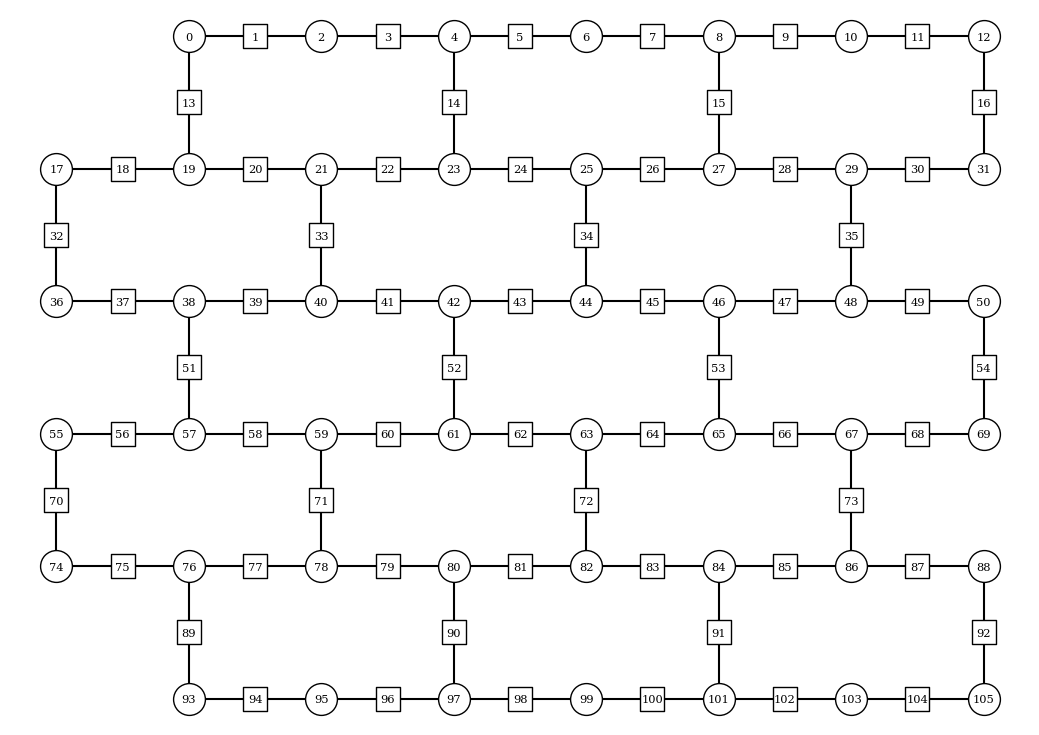

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 5

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

# Simulation settings

In [4]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB
from utils.execrecord import ExecutionRecord

lattice_dims = (plaquette_width, plaquette_height)
J = 0
h = 0
lamb = 1
g = 10

x_basis = False

fractional_gates = False

string = [27, 26, 34, 43, 52, 60, 71, 78]

final_time = 5
dt = 0.5
steps = 40
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 150000
confidence = 0.7

odr = True
flip_threshold = None
all_or_first_layout_qubit = True
forbidden_qubits = []
max_layouts = 5

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = None #"Curated data/"

# Error guarantees

In [ ]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"With provided the hardware error Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

In [ ]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice,J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

# Circuit generation & observables

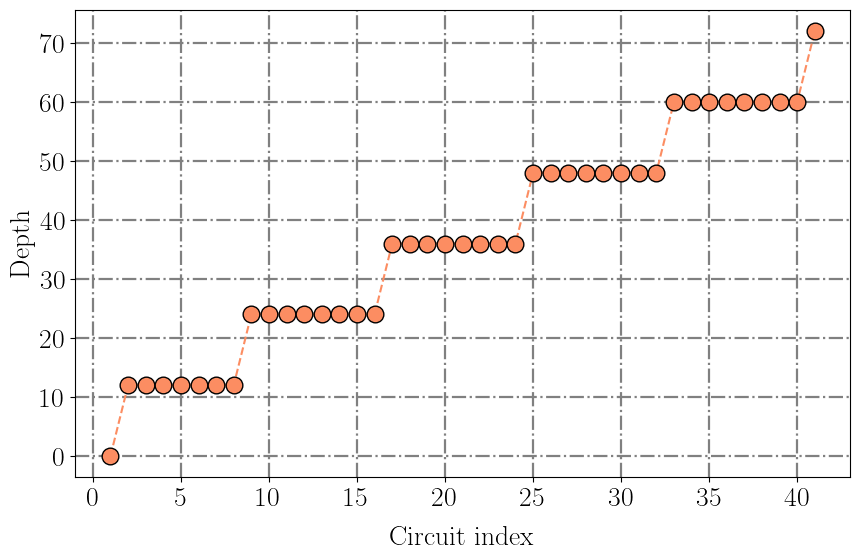

In [5]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]
circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g, layouts, x_basis, True, False)
# if os.path.exists(circuits_filepath):
#     circuits = load_many_layout_circs(circuits_filepath)
# else:
#     circuits = string_quench_simulation_circuits_dt(*circs_args)
    # save_many_layout_circs(circuits_filepath, circuits)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
# extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    odr_circuits_filepath = os.path.join(circ_folder_path, f"z2hex_odr_compuncomp_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
    odr_func_args = (lattice, J, h, lamb, final_time, dt, steps, backend, g, string, layouts, x_basis)
    if os.path.exists(odr_circuits_filepath):
        odr_circuits = load_many_layout_circs(odr_circuits_filepath)
    else:
        odr_circuits = odr_compuncomp_circuits_dt(*odr_func_args)
        if os.path.isdir(os.path.dirname(circuits_filepath)):
            save_many_layout_circs(odr_circuits_filepath, odr_circuits)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

plot_circuit_arr_depth(circuits[0])

# Load jobs with the same options

In [75]:
from utils.postselection_multithreaded import load_postselected_jobs
import pickle
import os

overwrite = False
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_ft_{flip_threshold}.npy")
else:
    curated_data_filepath = ""

if overwrite or not os.path.exists(curated_data_filepath):
    if odr:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True)
    else:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True)
    if curated_data_filepath:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

In [72]:
from utils.postselection_multithreaded import load_postselected_jobs
samples = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True)

In [74]:
maxval = max(samples[0].values())
for k, v in samples[0].items():
    if v == maxval:
        mk = k
        break
print(maxval)
print(mk)
print([i for i, c in enumerate(mk[::-1]) if c == "1"])

71044
0000000000000000000000000001000000100000000001000000010000000010000000010000001100000000000000000000000000
[26, 27, 34, 43, 52, 60, 71, 78]


In [58]:
samples.shape

(5, 41)

In [40]:
psamples.shape

(41,)

In [69]:

import pickle
with open("/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_marrakesh_px_3_py_5_maxt_5_dt_0.5_steps_40_J_0.0000_h_0.0000_lamb_1.0000_g_10_fqb_True_string_27-26-34-43-52-60-71-78_xbasis_False_ft_None.npy", "rb") as f:
    observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

In [70]:
maxval = max(postselected_samples_dicts[0][0][0].values())
for k, v in postselected_samples_dicts[0][0][0].items():
    if v == maxval:
        mk = k
        break
print(maxval)
print(mk)
print([i for i, c in enumerate(mk[::-1]) if c == "1"])

12460
0000000000000000000000000001000000100000000001000000010000000010000000010000001100000000000000000000000000
[26, 27, 34, 43, 52, 60, 71, 78]


In [49]:
from utils.postselection import combine_samples_dicts
combined_samples_dicts = combine_samples_dicts(*postselected_samples_dicts[0][:, 0])

In [51]:
maxval = max(combined_samples_dicts.values())
for k, v in combined_samples_dicts.items():
    if v == maxval:
        mk = k
        break
print(maxval)
print(mk)
print([i for i, c in enumerate(mk[::-1]) if c == "1"])

71238
0000000000000000000000000001000000100000000001000000010000000010000000010000001100000000000000000000000000
[26, 27, 34, 43, 52, 60, 71, 78]


In [41]:
maxval = max(samples[0].values())
for k, v in samples[0].items():
    if v == maxval:
        mk = k
        break
print(maxval)
print(mk)
print([i for i, c in enumerate(mk[::-1]) if c == "1"])

2338
0000000000000000000000000011000000100000000100000000100000001000000000010000001000000000000000000000000000
[27, 34, 45, 53, 62, 71, 78, 79]


In [43]:
sum(samples[0].values())

150000

In [44]:
sum(psamples[0].values())

150000

In [45]:
maxval = max(psamples[0].values())
for k, v in psamples[0].items():
    if v == maxval:
        mk = k
        break
print(maxval)
print(mk)
print([i for i, c in enumerate(mk[::-1]) if c == "1"])

31403
0000000000000000000000000001000000100000010101000000100000001000000000010000001100000000000000000000000000
[26, 27, 34, 45, 53, 60, 62, 64, 71, 78]


In [21]:
sum(psamples[0].values())

1230000

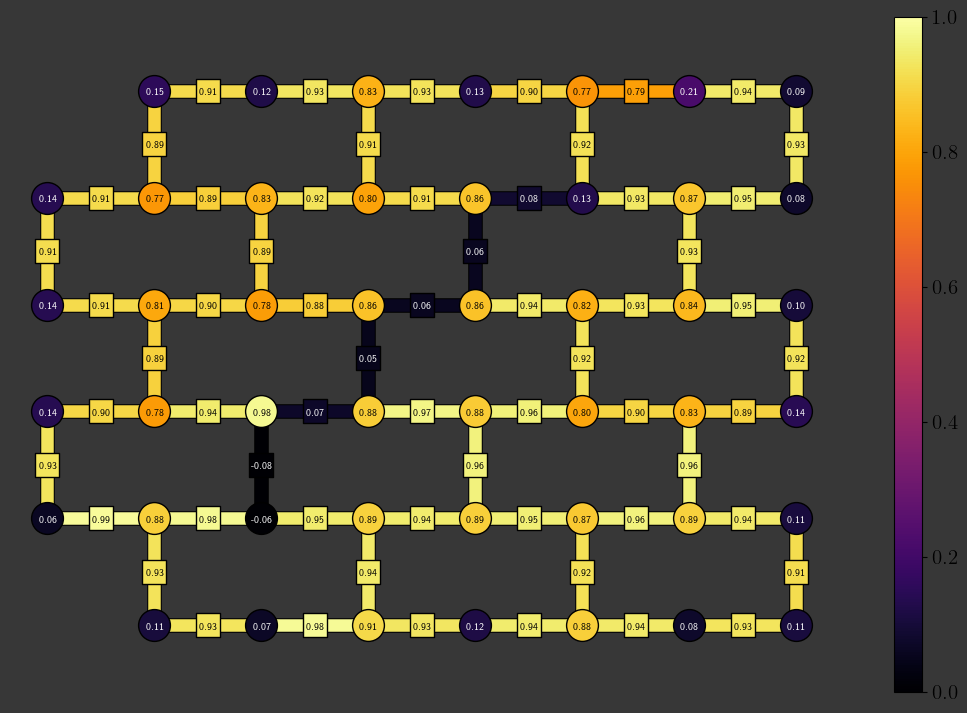

In [82]:
from z2hex.plotting import local_observable_plot

job_index = 39

local_observable_plot((1-observables[0][job_index])/2, lattice, cmap_range=[0, 1], dark_theme=True)

# Debug

## Discarded samples

In [ ]:
from utils.postselection import initialize_postselection
from utils.plotting import plot_discarded_samples
from utils.circs import depth2qb
import matplotlib.pyplot as plt

flip_thresholds = np.arange(0, 11, 2)
regression = True
plot_filepath = ""
cmap = plt.get_cmap("Set2")
x_ticks = np.array([depth2qb(circ) for circ in circuits[0]])[np.linspace(0, len(circuits[0])-1, 6, dtype=int)]
x_ticks_upper_func = lambda t: np.ceil(t//dt*6).astype(int)

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

plot_discarded_samples(samples_dicts, postselection_ops, flip_thresholds, circs_layouts=layouts, cmap=cmap, x_ticks=x_ticks, x_ticks_upper_func=x_ticks_upper_func, x_label="t", x_label_upper="2Qb Depth", regression=True, legend=True)

# Auxiliar observables cells

In [ ]:
from utils.postselection import initialize_postselection

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

In [ ]:
from utils.postselection import combine_samples_dicts

all_layouts_postselected_samples = [postselected_samples_dicts[0][i][0] for i in range(len(circuits))]
combined_postselected_samples = combine_samples_dicts(*all_layouts_postselected_samples)

all_layouts_odr_postselected_samples = [postselected_samples_dicts[1][i][0] for i in range(len(circuits))]
combined_odr_postselected_samples = combine_samples_dicts(*all_layouts_odr_postselected_samples)

In [ ]:
from utils.postselection import measure_diagonal_observables

real_observables, real_observables_confidence = measure_diagonal_observables(combined_postselected_samples, diagonal_observables, confidence=0.6)
odr_observables, odr_observables_confidence = measure_diagonal_observables(combined_odr_postselected_samples, diagonal_observables, confidence=0.6)

In [ ]:
from utils.odr import compute_depolarizing_probability, renormalize_observable

p_arr = compute_depolarizing_probability(odr_observables, 1, 0, odr_circuits[0][0].num_qubits)
clean_expectation_values, clean_expectation_values_confidence = renormalize_observable(real_observables, p_arr, 0, circuits[0][0].num_qubits, [-1, 1], expected_observable_arr=1, observable_confidence=real_observables_confidence)

In [ ]:
clean_expectation_values_confidence

In [ ]:
observables[0][0]